# ML1_Pipeline + Model

Ce notebook est en plusieurs étapes :
1. Comment charger et préparer les données
2. Comment utiliser correctement train_test_split
3. Comment créer des pipelines de prétraitement
4. Comment implémenter et évaluer un modèle de régression

## Objectif
Prédire l'année de plantation des arbres en utilisant les bonnes pratiques de Machine Learning.

## 1. Import des bibliothèques nécessaires et chargement des données.

Nous utilisons plusieurs bibliothèques essentielles :
- pandas et numpy : pour la manipulation des données
- sklearn : pour le Machine Learning
- matplotlib : pour la visualisation

In [2]:
# Les libraries nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

Nous chargeons les données depuis le fichier pickle qui contient notre dataset nettoyé.

In [3]:
# Chargement des données depuis le fichier pickle
df = pd.read_pickle('/home/sami.chircop@Digital-Grenoble.local/Documents/ML1/data/trees.pkl')

df['Latitude'] = df['Latitude'].map(lambda x:float(x))
df['Longitude'] = df['Longitude'].map(lambda x:float(x))
df['adr_secteur'] = df['adr_secteur'].map(lambda x:str(x))

## 2. Préparation des données pour le ML et séparation train_test

Première étape importante : supprimer les nan de la target puis séparer nos variables explicatives (features) de notre variable cible (target).

Deuxième étape : separation Train-Test

In [4]:
annee = df.pop('anneedeplantation')

In [5]:
# Suppression des lignes sans année de plantation
# On peut utiliser la méthode *dropna()* pour supprimer les lignes où la anneedeplantation est NaN
#DEJA FAIT

# Séperation train/test
# On peut utiliser la méthode *train_test_split()* de scikit-learn pour séparer les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(df, annee, random_state=28)

## [Optionnel] Comment on peut remplir les valeurs manquantes sans utiliser le pipeline?

In [6]:
# Remplir les valeurs manquantes avec la valeur la plus fréquente pour chaque colonne concernée

## [Optionnel] Création de nouvelles variables (Feature Engineering)

In [7]:
# Code

## 3. Création des pipelines de prétraitement

Les pipelines sont essentiels pour :
1. Automatiser les transformations
2. Éviter le data leakage
3. Assurer la cohérence entre train et test

### 3.1 Préparation des données & modèle de base

Nous préparons les données en utilisant un pipeline `scikit-learn` :
- **OneHotEncoder** pour les variables catégorielles
- **StandardScaler** pour les variables numériques
- **LinearRegression** comme modèle de base

In [8]:
# Quelles sont les variables catégorielles et variables numériques ?
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector as selector

# OneHotEncoder ?
#Toute sauf latitude et longitude
cat_var = df.select_dtypes(include=str).columns.tolist()

# StandardScaler ?
#latitude et longitude
num_var = df.select_dtypes(exclude=str).columns.tolist()

pipeline = ColumnTransformer([
    ("Numerical standardization", StandardScaler(), num_var),
     ("Categorical standardization", OneHotEncoder(handle_unknown='ignore'), cat_var)
])
#ridge needs sparce = False
X_prepared = pipeline.fit_transform(X_train)
X_test_prepared = pipeline.transform(X_test)


In [9]:
# [OPTIONNEL] Vérification rapide des valeurs manquantes
# Doit etre 0 pour toutes les colonnes pour le train et le test
X_train.isna().sum(axis=0)
X_test.isna().sum(axis=0)

sous_categorie             0
sous_categorie_desc        0
adr_secteur                0
genre_bota                 9
espece                   301
stadededeveloppement     635
collectivite              24
hauteurarbre            1444
portarbre               2787
structure                 38
typenature              2787
Latitude                   0
Longitude                  0
dtype: int64

## 4. Evaluation avec LinearRegression et plusieurs métriques :
- **MAE** (Mean Absolute Error)
- D'autres?

Ce modèle simple nous servira de point de comparaison pour des modèles plus avancés (comme les arbres de décision ou les forêts aléatoires).

In [10]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_prepared, y_train)

# predict y values for testing data set
y_pred_test = cross_val_predict(lin_reg, X_test_prepared, y_test, cv = 5)

#Cross-validation
cv_scores = cross_val_score(lin_reg, X_prepared, y_train, cv = 5, scoring='neg_mean_squared_error')
print('mean CV MSE:',np.mean(-cv_scores))
print('std CV MSE:',np.std(-cv_scores))

# evaluate MAE
mae_test = mean_absolute_error(y_test, y_pred_test)
print('test MAE: {0}'.format(mae_test))

# evaluate MSE
mse_test = mean_squared_error(y_test, y_pred_test)
print('test MSE: {0}'.format(mse_test))

# evaluate MSE
rmse_test = root_mean_squared_error(y_test, y_pred_test)
print('test MSE: {0}'.format(rmse_test))

mean CV MSE: 122.08635672802248
std CV MSE: 2.4147199399311834
test MAE: 8.724931889045783
test MSE: 136.10106558314686
test MSE: 11.666236136095774


## 5. Visualisation des prédictions

Visualisons la relation entre les valeurs réelles et prédites :

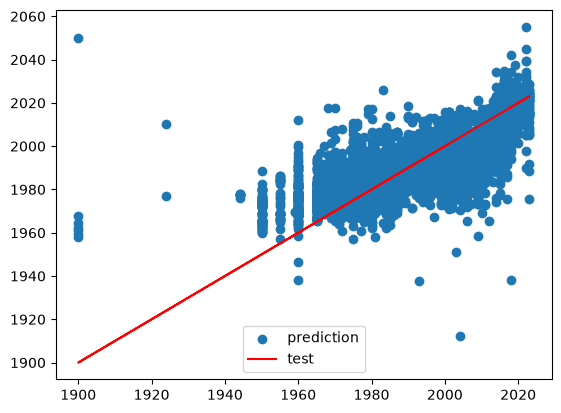

In [11]:
# Code
plt.scatter(y_test, y_pred_test)
plt.plot(y_test,y_test, 'r')
plt.legend(['prediction','test'])

## Conclusion

This model sucks as hell.

In [12]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

#standardize data
preprocessor = ColumnTransformer(
    transformers=[
        ("Numerical standardization", StandardScaler(), num_var),
        ("Categorical standardization", OneHotEncoder(handle_unknown='ignore'), cat_var)
        ]
        )

full_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor), 
        ("classifier", Ridge())
        ]
)

param_grid = {
    'classifier__alpha': [(10.0 ** n) for n in np.arange(-8,8)]
}

#ridge needs sparce = False
model = GridSearchCV(full_pipeline, param_grid, cv=5, scoring='neg_mean_squared_error')
model.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...r', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__alpha': [np.float64(1e-08), np.float64(1e-07), ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls

In [13]:
model_res = pd.DataFrame(model.cv_results_)

y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
best_mse = -model.best_score_

print('CV-MSE for Standardized Ridge model : ', best_mse)
print('Test MSE for Standardized Ridge model: ', mse)

CV-MSE for Standardized Ridge model :  121.56991670025438
Test MSE for Standardized Ridge model:  126.30114409994044


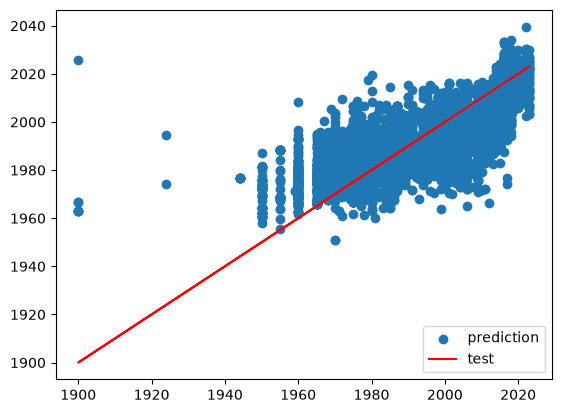

In [14]:
# Code
plt.scatter(y_test, y_pred)
plt.plot(y_test,y_test, 'r')
plt.legend(['prediction','test'])